   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB
None
       total_bill         tip        size
count  244.000000  244.000000  244.000000
mean    19.785943    2.998279    2.569672


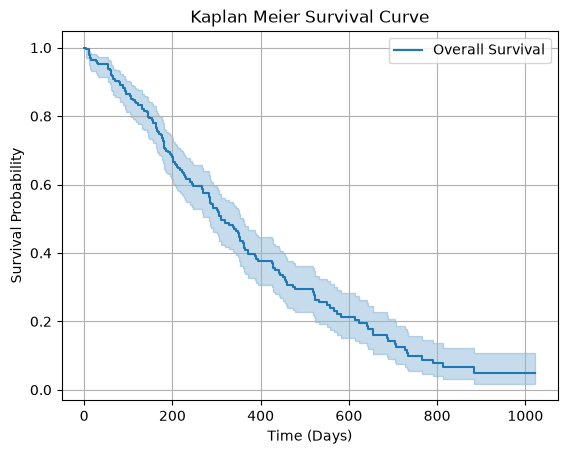

Survival at 100 days 0.863968967645243
Survival at 200 days 0.6802728622230085
Survival at 365 days 0.4092416244600636
Median Survival Time 310.0


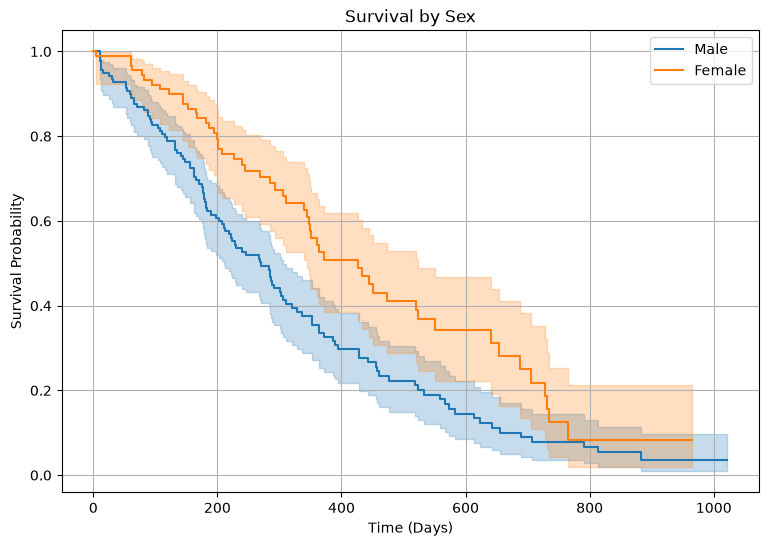

Male median survival: 270.0
Female median survival: 426.0
   test_statistic         p  -log2(p)
0       10.326742  0.001311  9.574936
Log-Rank Test Statistic: 10.326741954885627
P-value: 0.0013111645203554936
There is a statistically significant difference in survival between males and females.
%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
    mpg  cylinders  displacement  horsepower  weight  acceleration  \
0  18.0          8         307.0       130.0    3504          12.0   
1  15.0          8         350.0       165.0    3693          11.5   
2  18.0          8         318.0       150.0    3436          11.0   
3  16.0          8         304.0       150.0    3433          12.0   
4  17.0          8         302.0       140.0    3449          10.5   

   model_year origin                       name  
0          70    usa  chevrolet chevelle malibu  
1          70    usa          buick skylark 320  
2          70    usa         plymouth satellite  
3          70    usa    

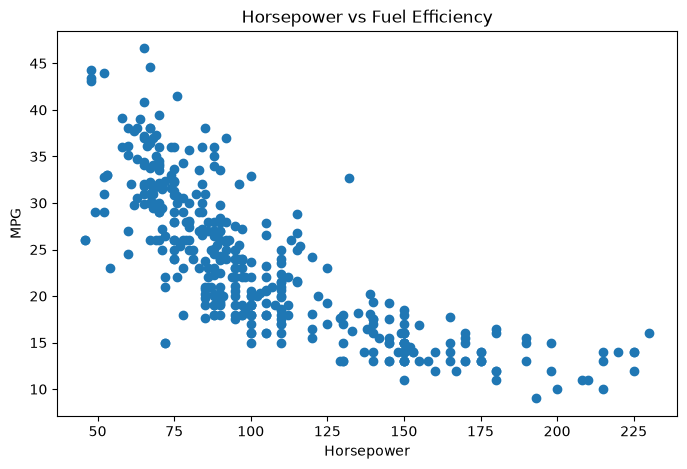

Linear Regression
RMSE: 4.706722545876633
R2: 0.5659681822256184

Degree: 2
RMSE: 4.291499481069298
R2: 0.639170114701326

Degree: 3
RMSE: 4.3500426362104445
R2: 0.6292583325719339

Degree: 4
RMSE: 4.55517067568273
R2: 0.5934689894297029
---------------------------------------------------
Degree 1: 4.706722545876633 0.5659681822256184
Degree 2 RMSE: 4.291499481069298 R2: 0.639170114701326
Degree 3 RMSE: 4.3500426362104445 R2: 0.6292583325719339
Degree 4 RMSE: 4.55517067568273 R2: 0.5934689894297029
------------------------------------------------------


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


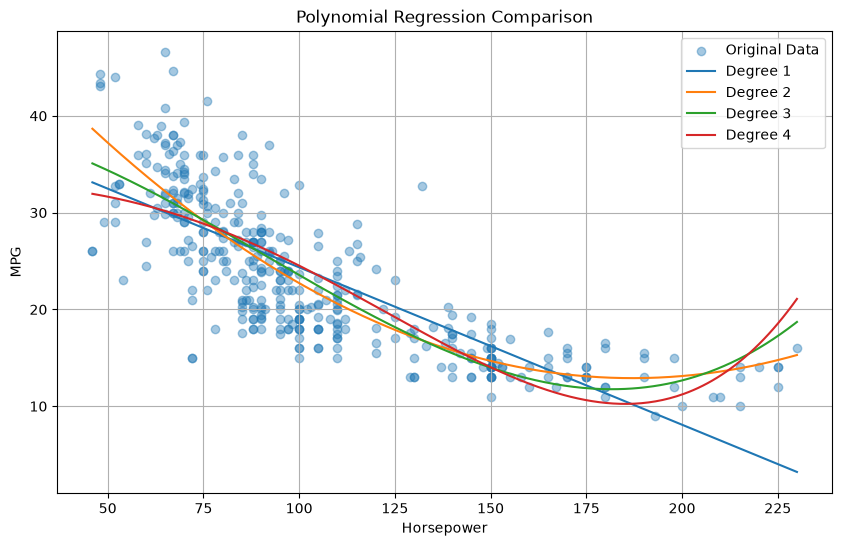

%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  target  
0 -0.002592  0.019907 -0.017646   151.0  
1 -0.039493 -0.068332 -0.092204    75.0  
2 -0.002592  0.002861 -0.025930   141.0  
3  0.034309  0.022688 -0.009362   206.0  
4 -0.002592 -0.031988 -0.046641   135.0  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-n

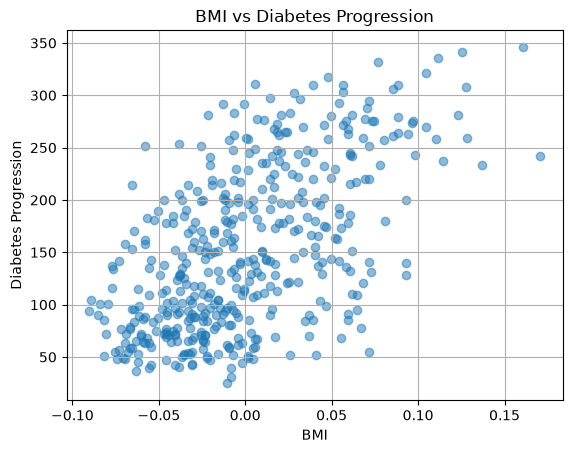

Linear Regression
RMSE: 63.73245584860925
R2: 0.23335039815872138

Knots: 3
RMSE: 64.2928659333475
R2: 0.2198085660568837

Knots: 5
RMSE: 63.623239164197
R2: 0.23597572250021648

Knots: 7
RMSE: 64.70758090801895
R2: 0.20971100381559793
------------------------------------------------------


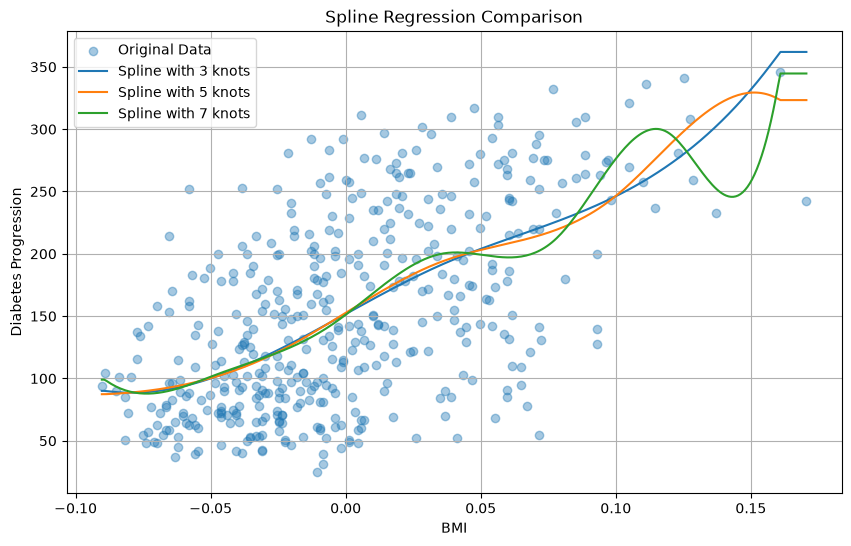

TypeError: cannot unpack non-iterable int object

In [61]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error

df = sns.load_dataset("tips")
print(df.head())
print(df.info())
print(df.describe())
print(df.isnull().sum())

X = df[["total_bill","tip","sex","smoker","day","time"]]
Y = df["size"]
X = pd.get_dummies(X,drop_first=True,dtype=int)
print(X.head())
print("Features:", X.columns.tolist())
print("Target:", Y.name)

X_train,X_test,Y_train,Y_test = train_test_split(
    X,Y,test_size = 0.2,random_state = 42
)

X_train_sm = sm.add_constant(X_train)
X_test_sm = sm.add_constant(X_test)

model = sm.GLM(
    Y_train,
    X_train_sm,
    family = sm.families.Poisson()
)

result = model.fit()

print(result.summary())

coefficients = pd.DataFrame({
    "Coefficients" : result.params,
    "P-Value" : result.pvalues
})

coefficients["Significance"] = np.where(
    coefficients["P-Value"] < 0.05,
    "Significant",
    "Non Significant"
)

print(coefficients)

Y_pred = result.predict(X_test_sm)

predictions = pd.DataFrame({
    "Actual size" : Y_test,
    "Predicted size" : Y_pred
})
predictions["Rounded Predictions"] = np.rint(Y_pred).astype(int)
print(predictions.head(10))

MAE = mean_absolute_error(Y_test,Y_pred)
print("MAE :",MAE)



print("%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%")



import pandas as pd
import matplotlib.pyplot as plt

from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test
from lifelines.datasets import load_lung

df = load_lung()
print(df.head())
print(df.info())
print(df.isnull().sum())
print(df.describe())
print(df["status"].value_counts)

T = df["time"]
E = df["status"].astype(int)

print("Total patients", len(df))
print("Event Occurred", (E==1).sum())
print("Censored", (E==0).sum())

kmf = KaplanMeierFitter()
kmf.fit(T,event_observed = E, label ="Overall Survival")
kmf.plot_survival_function()

plt.title("Kaplan Meier Survival Curve")
plt.xlabel("Time (Days)")
plt.ylabel("Survival Probability")
plt.grid()
plt.show()

print("Survival at 100 days", kmf.predict(100))
print("Survival at 200 days", kmf.predict(200))
print("Survival at 365 days", kmf.predict(365))
print("Median Survival Time", kmf.median_survival_time_)

male = df[df["sex"]==1]
female = df[df["sex"]==2]

kmf_male = KaplanMeierFitter()
kmf_female = KaplanMeierFitter()

kmf_male.fit(
    male["time"],
    event_observed = male["status"],
    label = "Male"
)

kmf_female.fit(
    female["time"],
    event_observed = female["status"],
    label = "Female"
)

plt.figure(figsize=(9,6))

kmf_male.plot_survival_function()
kmf_female.plot_survival_function()

plt.title("Survival by Sex")
plt.ylabel("Survival Probability")
plt.xlabel("Time (Days)")
plt.grid()
plt.show()

print("Male median survival:",
      kmf_male.median_survival_time_)

print("Female median survival:",
      kmf_female.median_survival_time_)

result = logrank_test(
    male["time"],
    female["time"],
    event_observed_A = male["status"],
    event_observed_B = female["status"]
)

print(result.summary)

print("Log-Rank Test Statistic:", result.test_statistic)
print("P-value:", result.p_value)

if result.p_value < 0.05:
    print("There is a statistically significant difference in survival between males and females.")
else:
    print("There is no statistically significant difference in survival between males and females.")




print("%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%")



import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, r2_score

df = sns.load_dataset("mpg")

df = df.dropna(subset=['horsepower'])
print(df.head())

print(df[['horsepower', 'mpg']].info())
print(df[['horsepower', 'mpg']].describe())
print("Missing values:\n", df[['horsepower', 'mpg']].isnull().sum())

X = df[['horsepower']]
y = df['mpg']

plt.figure(figsize=(8, 5))
plt.scatter(X, y)
plt.xlabel('Horsepower')
plt.ylabel('MPG')
plt.title('Horsepower vs Fuel Efficiency')
plt.show()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

y_pred = linear_model.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Linear Regression")
print("RMSE:", rmse)
print("R2:", r2)

results = {}

for degree in [2, 3, 4]:

    poly = PolynomialFeatures(degree=degree)

    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)

    model = LinearRegression()
    model.fit(X_train_poly, y_train)

    y_pred = model.predict(X_test_poly)

    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results[degree] = [rmse, r2]

    print("\nDegree:", degree)
    print("RMSE:", rmse)
    print("R2:", r2)
    
print("---------------------------------------------------")

linear_pred = linear_model.predict(X_test)

linear_rmse = np.sqrt(
    mean_squared_error(y_test, linear_pred)
)

linear_r2 = r2_score(y_test, linear_pred)

print("Degree 1:", linear_rmse, linear_r2)

for degree, values in results.items():
    print("Degree", degree,
          "RMSE:", values[0],
          "R2:", values[1])

print("------------------------------------------------------")


plt.figure(figsize=(10, 6))

plt.scatter(X, y, alpha=0.4, label="Original Data")

x_range = np.linspace(
    X['horsepower'].min(),
    X['horsepower'].max(),
    300
).reshape(-1, 1)

linear_curve = linear_model.predict(x_range)
plt.plot(x_range, linear_curve, label="Degree 1")

for degree in [2, 3, 4]:

    poly = PolynomialFeatures(degree=degree)

    X_train_poly = poly.fit_transform(X_train)
    X_range_poly = poly.transform(
        pd.DataFrame(x_range, columns=['horsepower'])
    )

    model = LinearRegression()
    model.fit(X_train_poly, y_train)

    y_curve = model.predict(X_range_poly)

    plt.plot(x_range, y_curve, label=f"Degree {degree}")

plt.xlabel("Horsepower")
plt.ylabel("MPG")
plt.title("Polynomial Regression Comparison")
plt.legend()
plt.grid()
plt.show()






print("%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%")





import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import SplineTransformer
from sklearn.metrics import mean_squared_error, r2_score

data = load_diabetes()

df = pd.DataFrame(
    data.data,
    columns=data.feature_names
)

df['target'] = data.target

print(df.head())
print(df.info())
print(df.isnull().sum())
print(df.describe())

X = df[['bmi']]
y = df['target']

plt.scatter(X, y, alpha=0.5)
plt.xlabel("BMI")
plt.ylabel("Diabetes Progression")
plt.title("BMI vs Diabetes Progression")
plt.grid()
plt.show()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

y_pred = linear_model.predict(X_test)

linear_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

linear_r2 = r2_score(y_test, y_pred)

print("Linear Regression")
print("RMSE:", linear_rmse)
print("R2:", linear_r2)

results = {}

for knots in [3, 5, 7]:

    spline = SplineTransformer(
        n_knots=knots,
        degree=3
    )

    X_train_spline = spline.fit_transform(X_train)
    X_test_spline = spline.transform(X_test)

    model = LinearRegression()

    model.fit(X_train_spline, y_train)

    y_pred = model.predict(X_test_spline)

    rmse = np.sqrt(
        mean_squared_error(y_test, y_pred)
    )

    r2 = r2_score(y_test, y_pred)

    results[knots] = [rmse, r2]

    print("\nKnots:", knots)
    print("RMSE:", rmse)
    print("R2:", r2)

print("------------------------------------------------------")

plt.figure(figsize=(10, 6))

plt.scatter(X, y, alpha=0.4, label="Original Data")

x_range = np.linspace(
    X['bmi'].min(),
    X['bmi'].max(),
    300
).reshape(-1, 1)

for knots in [3, 5, 7]:

    spline = SplineTransformer(
        n_knots=knots,
        degree=3
    )

    X_train_spline = spline.fit_transform(X_train)

    X_range_spline = spline.transform(
        pd.DataFrame(x_range, columns=['bmi'])
    )

    model = LinearRegression()

    model.fit(X_train_spline, y_train)

    y_curve = model.predict(X_range_spline)

    plt.plot(
        x_range,
        y_curve,
        label=f"Spline with {knots} knots"
    )

plt.xlabel("BMI")
plt.ylabel("Diabetes Progression")
plt.title("Spline Regression Comparison")
plt.legend()
plt.grid()
plt.show()

comparison = pd.DataFrame(
    [('Linear Regression', linear_rmse, linear_r2)] +
    [(f'Spline ({knots} Knots)', rmse, r2)
     for knots, model, spline, rmse, r2 in results],
    columns=['Model', 'RMSE', 'R2 Score']
)

print(comparison)

best_model = comparison.loc[comparison['RMSE'].idxmin()]

print("\nBest Performing Model:")
print(best_model)



print("#################################################################################################")




import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("https://archive.ics.uci.edu/ml/machine-learning-databases/00320/student-mat.csv", sep=";")

# a) Dataset inspection
print("Dimensions:", df.shape)
print("\nData Types:\n", df.dtypes)
print("\nSummary Statistics:\n", df.describe())
print("\nMissing Values:\n", df.isnull().sum())
print("\nDuplicate Records:", df.duplicated().sum())

# b) Preprocessing
df = df.drop_duplicates()
df = df.dropna()

cols = ['studytime', 'absences', 'failures', 'G1', 'G2', 'G3']

plt.figure(figsize=(12, 5))
sns.boxplot(data=df[cols])
plt.title("Box Plot for Outlier Detection")
plt.show()

# IQR method
for col in cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    print(col, "Outliers:", ((df[col] < Q1-1.5*IQR) | (df[col] > Q3+1.5*IQR)).sum())

# c) Descriptive Statistics
for col in ['studytime', 'absences', 'G3']:
    print("\n", col)
    print("Mean:", df[col].mean())
    print("Median:", df[col].median())
    print("Standard Deviation:", df[col].std())
    print("Minimum:", df[col].min())
    print("Maximum:", df[col].max())
    print("IQR:", df[col].quantile(0.75)-df[col].quantile(0.25))

# d) Pearson Correlation
pairs = [('studytime', 'G3'), ('absences', 'G3'), ('G1', 'G3'), ('G2', 'G3')]

for x, y in pairs:
    print(f"Correlation between {x} and {y}:", df[x].corr(df[y]))

# e) Visualizations

# 1. Distribution of final scores
sns.histplot(df['G3'], kde=True)
plt.title("Distribution of Final Grades")
plt.show()

# 2. Correlation Heatmap
plt.figure(figsize=(9, 6))
sns.heatmap(df.select_dtypes(include=np.number).corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

# 3. Study Time vs Final Grade
sns.scatterplot(data=df, x='studytime', y='G3')
plt.title("Study Time vs Final Grade")
plt.show()

# 4. Previous Grade vs Final Grade
sns.scatterplot(data=df, x='G2', y='G3')
plt.title("Previous Grade vs Final Grade")
plt.show()

# f) Strongest Relationship
correlations = df.corr(numeric_only=True)['G3'].drop('G3')
strongest = correlations.abs().idxmax()

print("\nStrongest Relationship:", strongest)
print("Correlation:", correlations[strongest])

print("Interpretation: The variable with the highest absolute correlation")
print("has the strongest linear relationship with the final grade.")



print("#################################################################################################")



import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# a) Load and inspect dataset
df = pd.read_csv("https://archive.ics.uci.edu/ml/machine-learning-databases/00222/bank-additional.zip", sep=";", compression="zip")

print("Dimensions:", df.shape)
print("\nData Types:\n", df.dtypes)
print("\nSummary Statistics:\n", df.describe(include='all'))
print("\nMissing Values:\n", df.isnull().sum())
print("\nDuplicate Records:", df.duplicated().sum())
print("\nTarget Distribution:\n", df['y'].value_counts())

# b) Preprocessing
df = df.drop_duplicates()
df = df.dropna()

X = df.drop('y', axis=1)
y = df['y'].map({'no': 0, 'yes': 1})

# Remove duration to avoid using information only known after the call
X = X.drop('duration', axis=1)

num_cols = X.select_dtypes(include=np.number).columns
cat_cols = X.select_dtypes(exclude=np.number).columns

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])

# c) Exploratory Data Analysis

sns.countplot(data=df, x='y')
plt.title("Subscription Distribution")
plt.show()

sns.barplot(data=df, x='job', y=y)
plt.xticks(rotation=45)
plt.title("Subscription by Job")
plt.show()

sns.barplot(data=df, x='education', y=y)
plt.xticks(rotation=45)
plt.title("Subscription by Education")
plt.show()

# d) Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5)
}

results = []

# e) Train and Evaluate Models
for name, model in models.items():

    clf = make_pipeline(preprocessor, model)
    clf.fit(X_train, y_train)

    pred = clf.predict(X_test)

    acc = accuracy_score(y_test, pred)
    prec = precision_score(y_test, pred, zero_division=0)
    rec = recall_score(y_test, pred, zero_division=0)
    f1 = f1_score(y_test, pred, zero_division=0)

    results.append([name, acc, prec, rec, f1])

    print("\n", name)
    print("Accuracy:", acc)
    print("Precision:", prec)
    print("Recall:", rec)
    print("F1 Score:", f1)

    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(name + " Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

# f) Comparative Performance Table
comparison = pd.DataFrame(results, columns=[
    'Model', 'Accuracy', 'Precision', 'Recall', 'F1 Score'
])

print("\nModel Comparison:\n", comparison)

best = comparison.loc[comparison['F1 Score'].idxmax()]
print("\nBest Model:", best['Model'])

# g) Conclusion
print("\nInterpretation:")
print("Precision measures correct positive predictions.")
print("Recall measures how many actual subscribers were identified.")
print("F1 Score balances precision and recall.")
print("The model with the highest F1 score provides the best balance")
print("between precision and recall for subscription prediction.")


print("#################################################################################################")



import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ttest_rel, norm

before = np.array([54, 61, 58, 67, 63, 55, 72, 69, 60, 64, 57, 71])
after = np.array([59, 65, 63, 72, 68, 61, 76, 74, 65, 69, 62, 77])

# a) Mean and Standard Deviation
print("Before Training:")
print("Mean:", np.mean(before))
print("Standard Deviation:", np.std(before, ddof=1))

print("\nAfter Training:")
print("Mean:", np.mean(after))
print("Standard Deviation:", np.std(after, ddof=1))

# b) Paired t-test
t_stat, p_value = ttest_rel(after, before)

# c) Hypothesis Testing
print("\nT-statistic:", t_stat)
print("P-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("Reject H0: Significant improvement after training.")
else:
    print("Fail to reject H0: No significant improvement.")

# d) Difference and Probability
diff = after - before

mean_diff = np.mean(diff)
std_diff = np.std(diff, ddof=1)

prob = norm.sf(5, loc=mean_diff, scale=std_diff)

print("\nDifferences:", diff)
print("Mean Difference:", mean_diff)
print("Standard Deviation of Differences:", std_diff)
print("Probability of Improvement > 5:", prob)

# e) Visualization
plt.plot(range(1, 13), before, marker='o', label='Before Training')
plt.plot(range(1, 13), after, marker='o', label='After Training')

plt.xlabel("Employee")
plt.ylabel("Programming Score")
plt.title("Before vs After Training Scores")
plt.legend()
plt.grid()
plt.show()

# f) Conclusion
print("\nConclusion:")
if p_value < alpha:
    print("Training produced a statistically significant improvement.")
else:
    print("Training did not produce a statistically significant improvement.")

if prob > 0.5:
    print("There is a high probability of improvement greater than 5 marks.")
else:
    print("The probability of improvement greater than 5 marks is relatively low.")







print("%%%%%%%%%%%%$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%")






import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binom, poisson

# PART A: BINOMIAL DISTRIBUTION

n = 20
p = 0.70

print("BINOMIAL DISTRIBUTION")
print("Exactly 15:", binom.pmf(15, n, p))
print("At least 16:", binom.sf(15, n, p))
print("Fewer than 10:", binom.cdf(9, n, p))
print("Expected value:", binom.mean(n, p))
print("Variance:", binom.var(n, p))

x = np.arange(0, n+1)
prob = binom.pmf(x, n, p)

plt.bar(x, prob)
plt.xlabel("Number of Positive Responses")
plt.ylabel("Probability")
plt.title("Binomial Distribution")
plt.show()

print("Binomial is appropriate because there are fixed 20 trials,")
print("two outcomes per trial, independent trials and constant probability.")


# PART B: POISSON DISTRIBUTION

arrivals = np.array([4,7,5,6,3,8,5,4,6,7,5,3,4,6,5,8,4,5,6,7])

lam = np.mean(arrivals)

print("\nPOISSON DISTRIBUTION")
print("Average arrival rate:", lam)
print("Exactly 5:", poisson.pmf(5, lam))
print("Fewer than 4:", poisson.cdf(3, lam))
print("More than 7:", poisson.sf(7, lam))

x = np.arange(0, max(arrivals)+1)
theoretical = poisson.pmf(x, lam)

observed = np.array([np.sum(arrivals == i) for i in x])
expected = len(arrivals) * theoretical

comparison = pd.DataFrame({
    "Arrivals": x,
    "Observed Frequency": observed,
    "Theoretical Probability": theoretical,
    "Expected Frequency": expected
})

print("\nObserved vs Theoretical:")
print(comparison)

plt.bar(x, observed/len(arrivals), alpha=0.6, label="Observed")
plt.plot(x, theoretical, 'ro-', label="Poisson")
plt.xlabel("Number of Arrivals")
plt.ylabel("Probability / Relative Frequency")
plt.title("Observed vs Poisson Distribution")
plt.legend()
plt.show()

print("Poisson is appropriate for counting arrivals in fixed time intervals,")
print("assuming independent arrivals and a constant average arrival rate.")
print("Compare observed and theoretical frequencies to assess model fit.")





print("%%%%%%%%%%%%$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%")





import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from collections import Counter

marks = np.array([
    56,72,68,81,75,63,91,48,67,73,
    85,59,77,69,54,88,71,64,79,82,
    61,74,93,57,66,76,70,52,84,62
])

# DESCRIPTIVE STATISTICS

mean = np.mean(marks)
median = np.median(marks)
mode = Counter(marks).most_common(1)[0][0]
minimum = np.min(marks)
maximum = np.max(marks)
variance = np.var(marks)
std = np.std(marks)
q1 = np.percentile(marks, 25)
q3 = np.percentile(marks, 75)
iqr = q3 - q1

print("Mean:", mean)
print("Median:", median)
print("Mode:", mode)
print("Minimum:", minimum)
print("Maximum:", maximum)
print("Range:", maximum-minimum)
print("Variance:", variance)
print("Standard Deviation:", std)
print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)

# Z-SCORE OF 91

z = (91-mean)/std
print("\nZ-score of 91:", z)

# NORMAL DISTRIBUTION PROBABILITIES

p_above80 = norm.sf(80, mean, std)
p_below60 = norm.cdf(60, mean, std)
p_between = norm.cdf(80, mean, std) - norm.cdf(60, mean, std)

print("\nP(X > 80):", p_above80)
print("P(X < 60):", p_below60)
print("P(60 < X < 80):", p_between)

# UNUSUAL OBSERVATIONS

z_scores = (marks-mean)/std
unusual = marks[np.abs(z_scores) > 2]

print("\nUnusual Marks:", unusual)

# ACTUAL VS PREDICTED PROPORTION ABOVE 80

actual = np.mean(marks > 80)

print("\nActual Proportion Above 80:", actual)
print("Normal Predicted Proportion:", p_above80)

# VISUALIZATION

plt.hist(marks, bins=8, density=True, alpha=0.6, label="Actual Marks")

x = np.linspace(minimum, maximum, 100)
plt.plot(x, norm.pdf(x, mean, std), 'r-', label="Normal Distribution")

plt.xlabel("Marks")
plt.ylabel("Density")
plt.title("Student Marks Distribution")
plt.legend()
plt.show()

print("\nInterpretation:")
print("Compare mean and median to understand symmetry.")
print("Mean approximately equal to median suggests a roughly symmetric distribution.")
print("Compare actual and predicted proportions to assess Normal fit.")
print("Correlation is not applicable here; z-scores identify unusual observations.")






print("%%%%%%%%%%%%$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%")






import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# DATA

df = pd.DataFrame({
    'Study_Hours': [2,3,4,5,6,7,8,9,10,4,7,9],
    'Attendance': [62,68,71,75,78,82,85,88,91,65,79,86],
    'Final_Marks': [48,52,58,61,67,72,76,81,85,55,70,79]
})

# MEAN AND STANDARD DEVIATION

print("Mean:")
print(df.mean())

print("\nStandard Deviation:")
print(df.std())

# COVARIANCE MATRIX

cov = df.cov()
print("\nCovariance Matrix:")
print(cov)

# CORRELATION MATRIX

corr = df.corr()
print("\nCorrelation Matrix:")
print(corr)

print("\nIndividual Correlations:")
print("Study Hours vs Marks:", corr.loc['Study_Hours','Final_Marks'])
print("Attendance vs Marks:", corr.loc['Attendance','Final_Marks'])
print("Study Hours vs Attendance:", corr.loc['Study_Hours','Attendance'])

# STRONGEST RELATIONSHIP

pairs = corr.abs().where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
print("\nStrongest Relationship:")
print(pairs.idxmax(), pairs.max())

# VISUALIZATIONS

sns.pairplot(df)
plt.show()

sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Correlation Heatmap")
plt.show()

# INTERPRETATION

for pair in [
    ('Study_Hours','Final_Marks'),
    ('Attendance','Final_Marks'),
    ('Study_Hours','Attendance')
]:
    r = corr.loc[pair[0], pair[1]]

    if abs(r) >= 0.7:
        strength = "Strong"
    elif abs(r) >= 0.4:
        strength = "Moderate"
    else:
        strength = "Weak"

    direction = "Positive" if r > 0 else "Negative"

    print(pair, ":", direction, strength, "Correlation")

print("\nCovariance depends on the scales of the variables,")
print("whereas correlation is standardized between -1 and +1.")
print("Higher study hours and attendance are associated with higher marks.")
print("However, correlation does not imply causation.")